# Tleco Neural Emulator – Stage 1: A Neural Surrogate of the Fokker-Planck Solver

**Table of Contents**

1. [Introduction](#1-introduction)
2. [Setup and Imports](#2-setup-and-imports)
3. [The Fokker-Planck Problem](#3-the-fokker-planck-problem)
4. [Solver Verification](#4-solver-verification)
5. [Parameter Design and Dataset](#5-parameter-design-and-dataset)
6. [Surrogate Model](#6-surrogate-model)
7. [Validation and Failure Modes](#7-validation-and-failure-modes)
8. [Conclusions and Next Steps](#8-conclusions-and-next-steps)
9. [References](#9-references)

## 1. Introduction

### About This Notebook

Project 2 of this portfolio builds a neural emulator of [Tleco](https://github.com/zkdavis/Tleco), the Fokker-Planck (FP) and radiative-transfer code used in Rueda-Becerril, Harrison & Giannios (2021, RHG21 hereafter) and described in Davis, Rueda-Becerril & Giannios (2024). The long-term goal is a fast, differentiable map from jet parameters $(\Gamma, \sigma, f_{\rm rec}, L_{\rm jet}, \dot m)$ to a blazar spectral energy distribution (SED). That map chains three pieces: a model driver, the FP solver for the electron energy distribution, and the radiation kernels (synchrotron, synchrotron self-Compton, external inverse Compton).

This notebook is **stage 1**: a surrogate of the numerical core alone, Tleco's FP solver `fp_findif_difu`. The FP solver is where Tleco spends its time-stepping effort, and its solution $n(\gamma, t)$ is the input to every radiation kernel. A surrogate of the solver is therefore the first building block of the full emulator, and it can be validated against analytic solutions, which a full SED emulator cannot.

### Scientific Question

Can a feed-forward neural network learn the parametric solution map

$$(p,\ \gamma_1,\ \gamma_2,\ \gamma_c,\ D_0,\ q,\ t) \longmapsto n(\gamma, t)$$

of the time-dependent FP equation with injection, radiative cooling, escape, and stochastic (turbulent) acceleration, to within the accuracy of the solver itself? Where in parameter space does it fail, and why?

### Approach

1. Map the physical problem onto the solver's coefficient convention and **verify** the mapping against three analytic solutions (Section 3–4).
2. Generate $\sim 1.8\times10^4$ solver trajectories over a scrambled Sobol design in a six-dimensional parameter space, each with 32 snapshots (Section 5).
3. Train multilayer perceptron (MLP) surrogates with two output heads, a Principal Component Analysis (PCA) basis and a direct per-bin output, and compare them (Section 6).
4. Validate on 2,048 held-out trajectories: error statistics, physics diagnostics (particle number, spectral indices, energy-peak position), failure-mode maps, a learning curve, and speed (Section 7).

## 2. Setup and Imports

The heavy lifting lives in the `fp_surrogate` package next to this notebook; the notebook only runs fast verification problems and loads saved artifacts. The full pipeline is:

```bash
.venv/bin/pytest                                             # solver verification tests
.venv/bin/python -m fp_surrogate.generate --split test  --out data/fp_surrogate/test.h5
.venv/bin/python -m fp_surrogate.generate --split train --out data/fp_surrogate/train.h5
.venv/bin/python -m fp_surrogate.train    --head pca    --tag pca_main
.venv/bin/python -m fp_surrogate.train    --head direct --tag direct_main
.venv/bin/python -m fp_surrogate.evaluate --tag pca_main
```

Training runs are tracked with MLflow (`mlflow ui --backend-store-uri sqlite:///mlflow.db`).

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=RuntimeWarning)

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tleco

from fp_surrogate import analytic as A
from fp_surrogate import config as cfg
from fp_surrogate import problem as P
from fp_surrogate.data import load, relevant_mask
from fp_surrogate.evaluate import EVAL_DIR, energy_peak, index_check, sample_errors
from fp_surrogate.model import FPSurrogate
from fp_surrogate.train import MODEL_DIR

plt.rcParams.update({"figure.dpi": 120, "font.size": 11})
G = cfg.GAMMA
print("tleco", tleco.__file__.split("site-packages/")[-1].split("/")[0])
print(f"output grid: {cfg.N_GAMMA} γ bins on [{cfg.GAMMA_MIN:g}, {cfg.GAMMA_MAX:g}], "
      f"{cfg.N_TOUT} snapshots on t/t_esc ∈ [1e{cfg.LOG_T_OUT_MIN:g}, 1e{cfg.LOG_T_OUT_MAX:g}]")
print(f"solver grid: {cfg.N_GAMMA_SOLVER} γ bins, {cfg.DEFAULT_SOLVER.substeps} substeps per snapshot interval")

tleco tleco
output grid: 128 γ bins on [1, 1e+08], 32 snapshots on t/t_esc ∈ [1e-3, 1e2]
solver grid: 509 γ bins, 64 substeps per snapshot interval


## 3. The Fokker-Planck Problem

### Solver convention

`fp_findif_difu` is an implicit Chang & Cooper (1970)-type finite-difference scheme. Reading its flux coefficients ($C = D/2$, $B = \tfrac12 \partial_\gamma D + \dot\gamma$) shows that it integrates

$$\frac{\partial n}{\partial t} = \frac{\partial}{\partial \gamma}\left[\frac12\frac{\partial (D\,n)}{\partial \gamma} + \dot\gamma\, n\right] + Q(\gamma) - \frac{n}{t_{\rm esc}},$$

with $\dot\gamma > 0$ meaning energy **loss**. Stochastic acceleration by turbulence with momentum-diffusion coefficient $D_{pp} = D_0\gamma^q$ obeys, in the ultra-relativistic limit,

$$\frac{\partial n}{\partial t} = \frac{\partial}{\partial \gamma}\left[D_{pp}\,\gamma^2\frac{\partial}{\partial\gamma}\left(\frac{n}{\gamma^2}\right) + \dot\gamma_{\rm cool}\, n\right] + Q - \frac{n}{t_{\rm esc}}.$$

Matching the two forms gives the arrays the solver must receive:

$$D = 2D_{pp}, \qquad \dot\gamma = \dot\gamma_{\rm cool} - (2+q)\,D_0\,\gamma^{q-1}.$$

The second term is the systematic energy gain from diffusion. For $q = 2$ this reproduces the convention of Tleco's own test suite ($\dot\gamma = C_0\gamma^2 - 4D_0/\gamma$ with $D = 2D_0$), and Section 4 verifies it against analytic solutions.

### A dimensionless problem family

The FP equation is linear in $(n, Q)$, so the injection rate is normalized to unity ($\int Q\,d\gamma = 1$) and time is measured in units of $t_{\rm esc}$. Every trajectory starts empty, $n(\gamma, 0) = 0$, with continuous injection:

| Input | Meaning | Range |
|---|---|---|
| $p$ | injection index, $Q \propto \gamma^{-p}$ on $[\gamma_1, \gamma_2]$ | 1.5–3.5 |
| $\log_{10}\gamma_1$ | injection lower cutoff | 0–3 |
| $\log_{10}(\gamma_2/\gamma_1)$ | injection width ($\gamma_2 \le 10^7$) | 1–5 |
| $\log_{10}\gamma_c$ | cooling break: $\dot\gamma_{\rm cool} = \gamma^2/(\gamma_c t_{\rm esc})$ | 1–6 |
| $\log_{10}(D_0 t_{\rm esc})$ | acceleration strength, $D_{pp} = D_0\gamma^q$ | −4–0 |
| $q$ | turbulence index (5/3 Kolmogorov, 2 hard-sphere) | 1.5–2 |
| $t/t_{\rm esc}$ | snapshot time | $10^{-3}$–$10^{2}$ |

The cooling term is synchrotron or Thomson inverse-Compton cooling ($\dot\gamma \propto \gamma^2$); $\gamma_c$ is the Lorentz factor at which the cooling time equals $t_{\rm esc}$. Acceleration balances cooling at $\gamma_{\rm eq} = [(2+q) D_0\gamma_c]^{1/(3-q)}$, which spans $\sim 10^{-2}$–$10^{6}$ across the box. The family therefore contains cooling-dominated power laws, broken power laws, and acceleration pile-ups.

The surrogate's target is $\log_{10} n$ on 128 log-spaced bins over $\gamma \in [1, 10^8]$, floored 15 dex below each snapshot's maximum.

## 4. Solver Verification

Before generating training data, the coefficient mapping and the solver accuracy are checked against three analytic solutions. These checks also fix the **solver error floor**: the surrogate cannot meaningfully be more accurate than the data it learns from. The same checks run as unit tests in `tests/test_fp_problem.py`.

### 4.1 Tleco's reference problems

(a) Hard-sphere acceleration balanced by cooling, with no escape: the zero-flux steady state is $n \propto \gamma^2 \exp[-2C_0 t_{\rm acc}(\gamma-1)]$. (b) The time-dependent Green's function of Park & Petrosian (1995, eq. 59) for $q = 3$ with escape. Both problems are built with `problem.transport`, the same function that builds the training data.

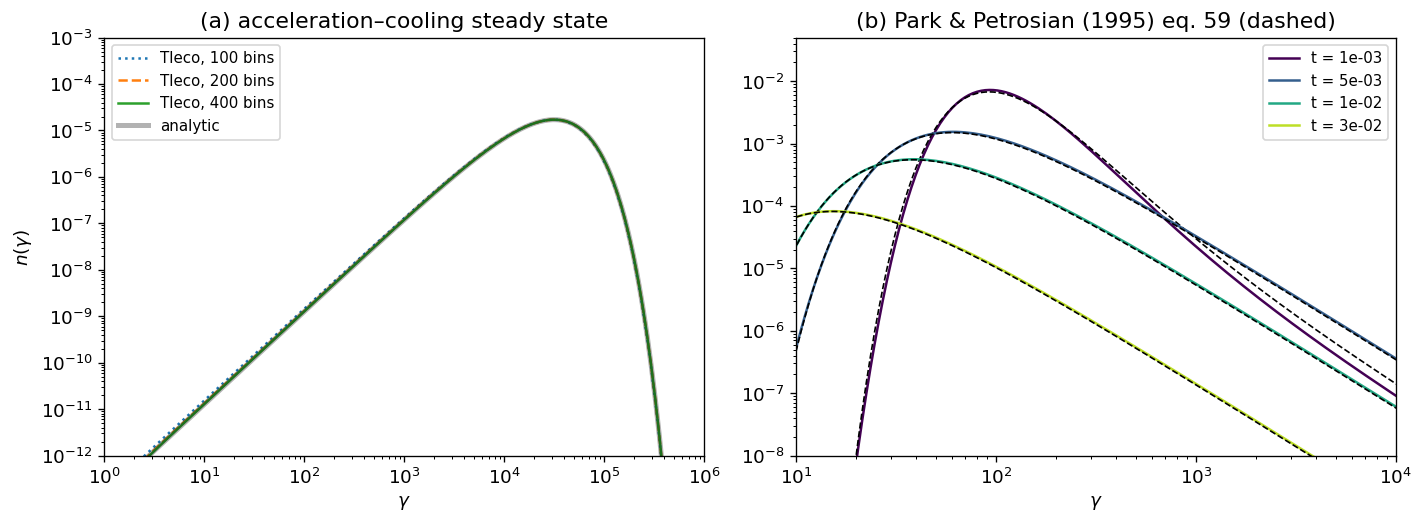

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) Acceleration-cooling steady state (Tleco comparison test; no escape)
c0 = 3.48e-11
tacc = 1 / (c0 * 10**4.5)
for numg, ls in [(100, ":"), (200, "--"), (400, "-")]:
    g = np.logspace(0, np.log10(1.5e8), numg)
    t = np.concatenate([[0.0], np.logspace(0, np.log10(300 * tacc), 800)])
    gdot, D = P.transport(g, c0, 0.5 / tacc, 2.0)
    n0 = np.where((g >= 1e4) & (g <= 1e6), 1.0, 0.0)
    n0 /= np.trapezoid(n0, g)
    n = P.evolve(n0, t, np.zeros_like(g), gdot, D, g=g, t_esc=1e200, out_idx=[len(t) - 1])[-1]
    axs[0].loglog(g, n, ls, label=f"Tleco, {numg} bins")
axs[0].loglog(g, A.acc_cool_steady_state(g, 1.0, c0, tacc), "k", lw=3, alpha=0.3, label="analytic")
axs[0].set(xlim=(1, 1e6), ylim=(1e-12, 1e-3), xlabel=r"$\gamma$", ylabel=r"$n(\gamma)$",
           title="(a) acceleration–cooling steady state")
axs[0].legend(fontsize=9)

# (b) Park & Petrosian (1995) eq. 59
g = np.logspace(0, np.log10(1.5e8), 400)
t = np.logspace(-4, -1, 800)
gdot, D = P.transport(g, 1.0, 1.0, 3.0)
n0 = A.park_petrosian_eq59(1e-4, g)
norm = np.trapezoid(n0, g)
ns = P.evolve(n0 / norm, t, np.zeros_like(g), gdot, D, g=g, t_esc=1.0)
for tt, c in zip([1e-3, 5e-3, 1e-2, 3e-2], plt.cm.viridis(np.linspace(0, 0.9, 4))):
    i = np.argmin(np.abs(t - tt))
    axs[1].loglog(g, ns[i], color=c, label=f"t = {t[i]:.0e}")
    axs[1].loglog(g, A.park_petrosian_eq59(t[i] + 1e-4, g) / norm, "k--", lw=1)
axs[1].set(xlim=(1e1, 1e4), ylim=(1e-8, 5e-2), xlabel=r"$\gamma$", title="(b) Park & Petrosian (1995) eq. 59 (dashed)")
axs[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

Both reference problems are reproduced, which confirms the coefficient mapping $D = 2D_{pp}$, $\dot\gamma = \dot\gamma_{\rm cool} - (2+q)D_0\gamma^{q-1}$:

* **(a)** The acceleration–cooling steady state converges with resolution: about 2.5% root-mean-square (RMS) relative error at 200 bins and 0.6% at 400 bins. Particle number is conserved to $10^{-10}$ (the test has no escape).
* **(b)** The time-dependent Park & Petrosian Green's function is matched to about 0.02 dex (median) at $t = 5\times10^{-3}$ and $10^{-2}$. The residual at $t = 10^{-3}$ in the high-energy tail is the memory of the initial condition, which is itself the analytic solution sampled at $t = 10^{-4}$ on a discrete grid.

### 4.2 Cooling + escape steady state, and grid convergence

With negligible diffusion, the steady state of injection + $\gamma^2$ cooling + escape is

$$n(\gamma) = \frac{\gamma_c t_{\rm esc}}{\gamma^2}\int_\gamma^\infty Q(\gamma')\, e^{-\gamma_c(1/\gamma - 1/\gamma')}\,d\gamma',$$

with index $p$ below $\gamma_c$ and $p+1$ above. This is an in-family problem, so it measures the error of the exact solver configuration used for the dataset.

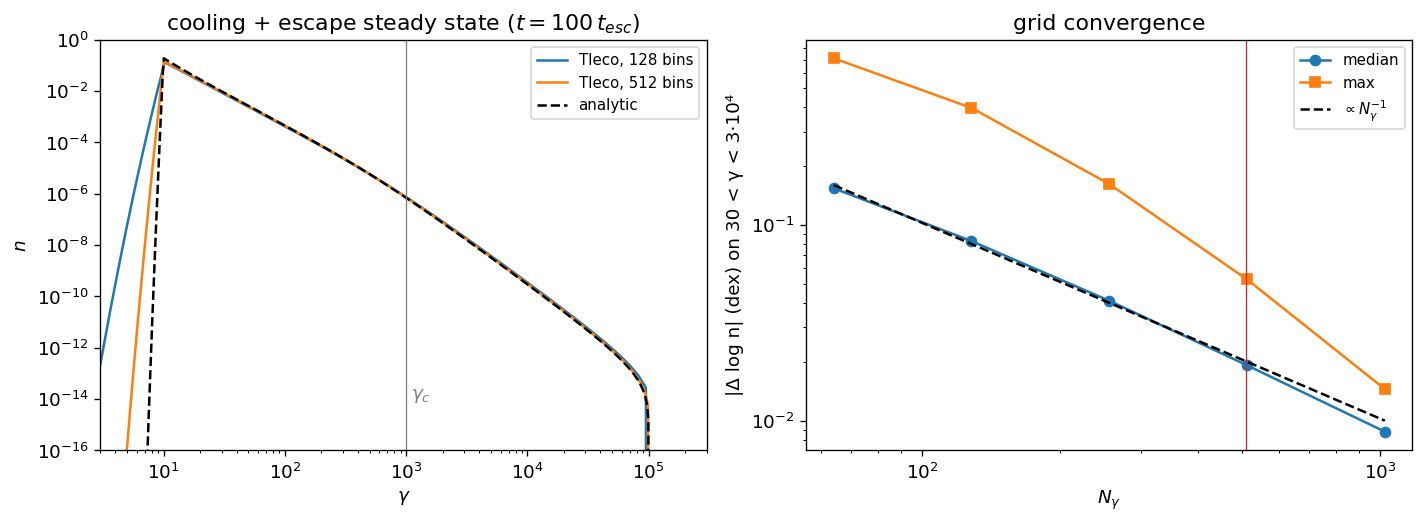

indices at t = 100 t_esc (expected p = 2.5 below γc, p+1 = 3.5 above):


  below: 2.568   above: 3.441


,N_γ,median |Δlog n|,max |Δlog n|
0,64,0.1541,0.7117
1,128,0.0828,0.3969
2,256,0.0410,0.1620
3,512,0.0192,0.0527
4,1024,0.0088,0.0145


In [3]:
COOL = np.array([2.5, 1.0, 4.0, 3.0, -12.0, 2.0])  # p, log γ1, log γ2/γ1, log γc, log D0, q
t_s, idx_s = P.solver_times()
rows = []
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for NG in [64, 128, 256, 512, 1024]:
    g = np.logspace(0, 8, NG)
    Q, gdot, D = P.coefficients(COOL, g)
    n = P.evolve(np.zeros_like(g), t_s, Q, gdot, D, g=g, out_idx=[idx_s[-1]])[-1]
    na = A.cooling_escape_steady_state(g, Q, gc=1e3)
    m = (g > 30) & (g < 3e4)
    err = np.abs(np.log10(n[m] / na[m]))
    rows.append({"N_γ": NG, "median |Δlog n|": np.median(err), "max |Δlog n|": err.max()})
    if NG in (128, 512):
        axs[0].loglog(g, n, label=f"Tleco, {NG} bins")
axs[0].loglog(g, na, "k--", label="analytic")
axs[0].axvline(1e3, color="gray", lw=0.8)
axs[0].text(1.1e3, 1e-14, r"$\gamma_c$", color="gray")
axs[0].set(xlim=(3, 3e5), ylim=(1e-16, 1), xlabel=r"$\gamma$", ylabel=r"$n$", title="cooling + escape steady state ($t = 100\,t_{esc}$)")
axs[0].legend(fontsize=9)
conv = pd.DataFrame(rows)
axs[1].loglog(conv["N_γ"], conv["median |Δlog n|"], "o-", label="median")
axs[1].loglog(conv["N_γ"], conv["max |Δlog n|"], "s-", label="max")
axs[1].loglog(conv["N_γ"], 0.08 * 128 / conv["N_γ"], "k--", label=r"$\propto N_\gamma^{-1}$")
axs[1].axvline(cfg.N_GAMMA_SOLVER, color="C3", lw=0.8)
axs[1].set(xlabel=r"$N_\gamma$", ylabel="|Δ log n| (dex) on 30 < γ < 3·10⁴", title="grid convergence")
axs[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
print("indices at t = 100 t_esc (expected p = 2.5 below γc, p+1 = 3.5 above):")
g = cfg.GAMMA_SOLVER
Q, gdot, D = P.coefficients(COOL, g)
n = P.evolve(np.zeros_like(g), t_s, Q, gdot, D, g=g, out_idx=[idx_s[-1]])[-1]
print(f"  below: {A.local_index(g, n, 30, 300):.3f}   above: {A.local_index(g, n, 3e3, 1e4):.3f}")
conv.round(4)

Two conclusions follow:

* **The scheme is first order in $\Delta\gamma$.** The error halves each time the grid is refined (dashed line). At the production output resolution of 128 bins (16 bins per decade), the solver's own truncation error is about 0.08 dex (median) and up to 0.4 dex near the injection edge. That error is not negligible next to a surrogate target of a few hundredths of a dex.
* **Design decision:** the reference solver runs on a **4× refined grid of 509 bins** containing every output bin, and its output is subsampled to 128 bins. This cuts the truncation error about 4× (0.02 dex median) for about 6× the cost per trajectory. The surrogate learns this more accurate solution while keeping a 128-dimensional output. The low-$\gamma$ side of the injection edge shows the scheme's numerical diffusion; it shrinks with resolution in the same way.

The late-time spectral indices, $p$ below $\gamma_c$ and $p+1$ above, are recovered to within 0.07.

### 4.3 Time-step convergence

Snapshots are taken at 32 log-spaced times. The solver advances with `substeps` log-uniform steps between consecutive snapshots (plus a lead-in from $t = 10^{-6}$). Errors on relevant bins (within 8 dex of the snapshot peak) are measured against a 512-substep reference for eight random parameter sets:

In [4]:
rng = np.random.default_rng(0)
lo, hi = cfg.PARAM_BOUNDS.T
thetas = lo + (hi - lo) * rng.random((8, cfg.N_PARAMS))
gs = cfg.GAMMA_SOLVER

def run(th, sub, ls=-6.0):
    Q, gdot, D = P.coefficients(th, gs)
    t, oi = P.solver_times(cfg.T_OUT, cfg.SolverConfig(substeps=sub, log_t_start=ls))
    return P.evolve(np.zeros_like(gs), t, Q, gdot, D, g=gs, out_idx=oi)[:, ::cfg.GAMMA_REFINE]

rows = []
for th in thetas:
    ref = P.to_log(run(th, 512, -8.0))
    rel = relevant_mask(ref)
    for sub in [8, 16, 32, 64, 128]:
        e = np.abs(P.to_log(run(th, sub)) - ref)[rel]
        rows.append({"substeps": sub, "median": np.median(e), "p99": np.percentile(e, 99)})
tconv = pd.DataFrame(rows).groupby("substeps").median()
tconv.round(5)

,median,p99
substeps,,
8,0.00011,0.20133
16,0.00006,0.10643
32,0.00003,0.05421
64,0.00001,0.02602
128,0.00001,0.01134


The implicit time stepping is also first order. With 64 substeps per snapshot interval (about 3,200 steps per trajectory), the median error is negligible ($10^{-5}$ dex). The 99th percentile, about 0.03 dex, sits in the fast-evolving tails at early times. This is the production setting: about 0.8 s per trajectory on one core.

### 4.4 A sign inconsistency in Tleco's cooling-only branch

When $\sum D < 10^{-150}$, `fp_findif_difu` falls back to `fp_findif_cool`. With the same $\dot\gamma$ convention as the diffusion branch, that branch is unstable; with $\dot\gamma$ negated it is stable and agrees with the diffusion branch. The two branches therefore use opposite sign conventions. Every problem in this notebook has $D_0 t_{\rm esc} \ge 10^{-4}$ and never takes the fallback path (asserted in the tests), but the inconsistency should be fixed upstream.

In [5]:
Q, gdot, _ = P.coefficients(COOL, gs)
D0 = np.zeros_like(gs)
n_bad = P.evolve(np.zeros_like(gs), t_s, Q, gdot, D0, g=gs, out_idx=[idx_s[-1]])[-1]
n_flip = P.evolve(np.zeros_like(gs), t_s, Q, -gdot, D0, g=gs, out_idx=[idx_s[-1]])[-1]
print(f"fp_findif_cool with the fp_findif_difu sign convention: max n = {n_bad.max():.2e}, min n = {n_bad.min():.2e}")
print(f"fp_findif_cool with γdot negated:                        max n = {n_flip.max():.2e}, min n = {n_flip.min():.2e}")

fp_findif_cool with the fp_findif_difu sign convention: max n = nan, min n = nan
fp_findif_cool with γdot negated:                        max n = 1.43e-01, min n = 0.00e+00


## 5. Parameter Design and Dataset

The six parameters are sampled with scrambled Sobol sequences (`scipy.stats.qmc`): $2^{14} = 16{,}384$ trajectories for training and validation, and an independent stream of $2^{11} = 2{,}048$ for testing. Each trajectory has 32 snapshots, giving 524,288 training-pool and 65,536 test samples. Train/validation splitting is done **by trajectory** (90/10), so no time slice of a held-out trajectory is ever seen in training.

In [6]:
import h5py

files = [cfg.DATA_DIR / "train.h5", cfg.DATA_DIR / "train_ext.h5", cfg.DATA_DIR / "test.h5"]
rows = []
for fp in files:
    with h5py.File(fp) as f:
        st, rt = f["status"][:], f["runtime_s"][:]
    rows.append({"file": fp.name, "trajectories": len(st), "ok": int(np.sum(st == 0)),
                 "failed": int(np.sum(st != 0)), "median s/traj": np.median(rt), "max s/traj": rt.max(),
                 "CPU-hours": rt.sum() / 3600})
pool = load(files[:2])
test = load(files[2])
print(f"train pool: {len(pool)} trajectories × {cfg.N_TOUT} snapshots = {len(pool) * cfg.N_TOUT:,} samples")
pd.DataFrame(rows).set_index("file").round(3)

train pool: 65536 trajectories × 32 snapshots = 2,097,152 samples


,trajectories,ok,failed,median s/traj,max s/traj,CPU-hours
file,,,,,,
train.h5,16384,16384,0,0.789,2.816,3.641
train_ext.h5,49152,49152,0,0.762,0.891,10.418
test.h5,2048,2048,0,0.764,1.285,0.435


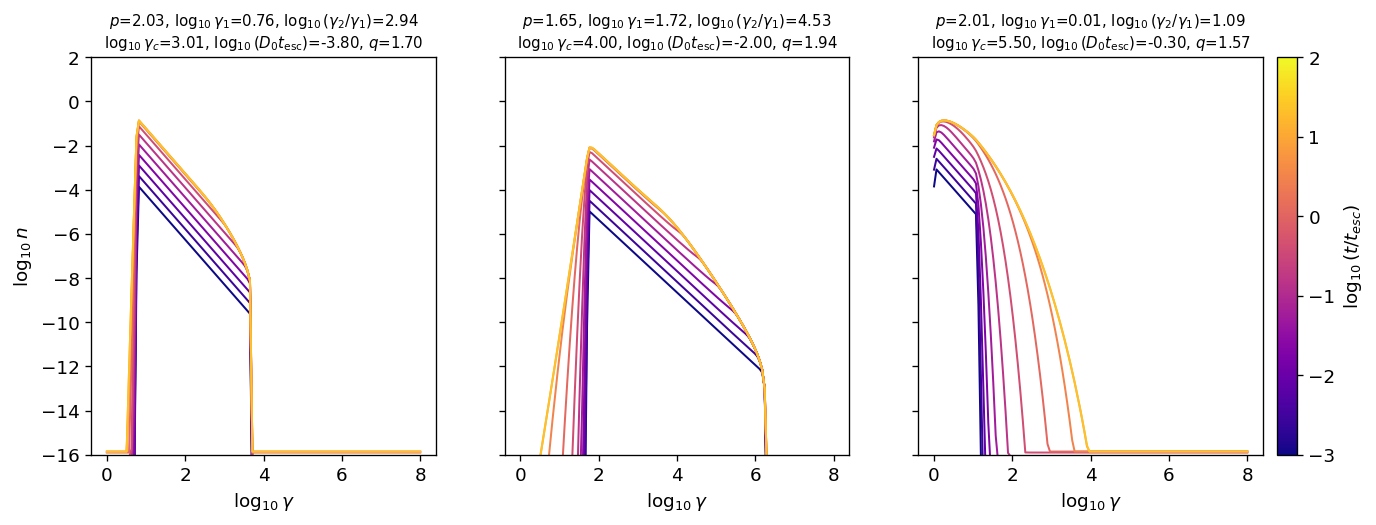

In [7]:
pick = [np.argmin(np.abs(pool.theta[:, 4] - v) + np.abs(pool.theta[:, 3] - w)) for v, w in [(-3.8, 3), (-2, 4), (-0.3, 5.5)]]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
cols = plt.cm.plasma(np.linspace(0, 0.9, cfg.N_TOUT))
for ax, i in zip(axs, pick):
    for k in range(0, cfg.N_TOUT, 3):
        ax.plot(np.log10(G), pool.log_n[i, k], color=cols[k], lw=1.2)
    d = P.unpack(pool.theta[i])
    items = [f"{cfg.PARAM_LABELS[k]}={v:.2f}" for k, v in d.items()]
    ax.set(title=", ".join(items[:3]) + "\n" + ", ".join(items[3:]), xlabel=r"$\log_{10}\gamma$", ylim=(-16, 2))
    ax.title.set_fontsize(9)
axs[0].set_ylabel(r"$\log_{10} n$")
sm = plt.cm.ScalarMappable(cmap="plasma", norm=plt.Normalize(cfg.LOG_T_OUT_MIN, cfg.LOG_T_OUT_MAX))
fig.colorbar(sm, ax=axs, label=r"$\log_{10}(t/t_{esc})$", pad=0.01)
plt.show()

Three representative trajectories, from left to right:

* **Cooling-dominated:** a power law with a cooling break, plus weak diffusion below $\gamma_1$.
* **Moderate acceleration:** diffusion fills $\gamma < \gamma_1$ and steepens the high-energy tail.
* **Strong acceleration with $\gamma_1 \approx 1$:** particles are pushed to an acceleration–cooling pile-up and the hard injection edges are erased.

The early snapshots ($t \ll t_{\rm esc}$, dark) are essentially $Q\,t$: power laws with **hard edges at $\gamma_1$ and $\gamma_2$** whose positions move with the parameters. These moving discontinuities are what the surrogate finds hardest (Section 7).

### Particle-number budget

Cooling and diffusion move particles in $\gamma$ without creating or destroying them, so with unit injection and escape the total number must follow $N(t) = 1 - e^{-t/t_{\rm esc}}$ exactly. This gives an exact check for every trajectory, independent of its parameters.

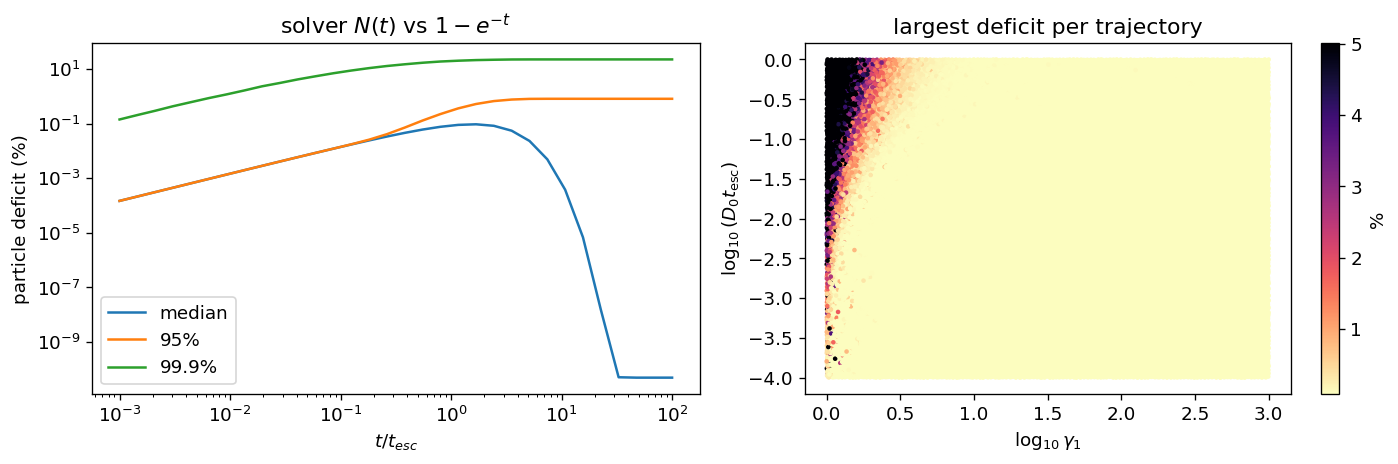

trajectories with >1% particle deficit: 4.6%


In [8]:
N_ana = A.number_budget(pool.t_out)
rel = pool.N_tot / N_ana - 1
worst = np.min(rel, axis=1)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].loglog(pool.t_out, np.percentile(-rel, [50, 95, 99.9], axis=0).T * 100, label=["median", "95%", "99.9%"])
axs[0].set(xlabel=r"$t/t_{esc}$", ylabel="particle deficit (%)", title=r"solver $N(t)$ vs $1-e^{-t}$")
axs[0].legend()
sc = axs[1].scatter(pool.theta[:, 1], pool.theta[:, 4], c=-worst * 100, s=3, cmap="magma_r", vmax=5)
axs[1].set(xlabel=cfg.PARAM_LABELS["log_g1"], ylabel=cfg.PARAM_LABELS["log_D0"], title="largest deficit per trajectory")
fig.colorbar(sc, ax=axs[1], label="%")
plt.tight_layout()
plt.show()
print(f"trajectories with >1% particle deficit: {np.mean(worst < -0.01) * 100:.1f}%")

The solver respects the number budget closely:

* **Baseline deficit:** every trajectory shares a deficit of at most 0.09% (peaking near $t \approx t_{\rm esc}$). This is the first-order time-stepping error of $dN/dt = 1 - N$.
* **Leakage through the $\gamma = 1$ boundary:** the large deficits are confined to injection that starts near $\gamma_1 \approx 1$ ($\log_{10}\gamma_1 \lesssim 0.5$), where diffusion and cooling push particles below the bottom of the grid. Their number is never *gained*, only lost.
* **How often it matters:** 4.6% of trajectories lose more than 1% of their particles; the worst loses 33%.

The ultra-relativistic FP equation is not valid near $\gamma \sim 1$ anyway, so this is a known limitation of the problem setup rather than a bug. The surrogate learns the solver *as it is*, and the number diagnostic in Section 7 therefore compares the surrogate with Tleco, not with $1 - e^{-t}$.

## 6. Surrogate Model

### Architecture

The input is the six parameters mapped to the unit cube plus $\log_{10} t$ mapped to $[0,1]$. A multilayer perceptron with SiLU activations maps it to $\log_{10} n$ on the 128 output bins. Two output heads are compared, trained with the **same loss**, mean squared error in $\log_{10} n$ over all bins:

* **PCA head:** the network predicts unit-variance PCA coefficients that are decoded by a fixed linear layer, $\log n = \bar y + \sum_k z_k s_k v_k$. This is the standard emulator compression (e.g. CosmoPower).
* **Direct head:** the network predicts all 128 bins, $\log n = \bar y + \sigma \odot z$.

The optimizer is AdamW with linear warm-up and cosine decay, batch 1,024, and early stopping on validation loss. Training runs on the Apple GPU (MPS) at under a second per epoch.

### How compressible is the solution manifold?

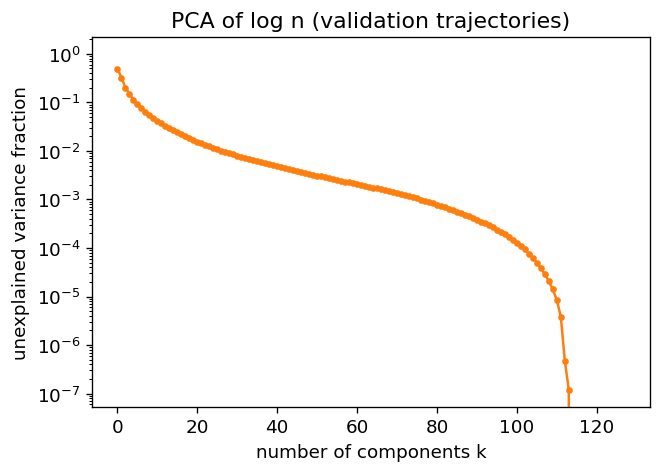

,median,p99 bin,p95 sample max
k,,,
8,0.4548,4.8175,6.3939
16,0.2068,3.5753,5.1446
24,0.1190,2.8139,4.4129
32,0.0769,2.1722,3.8824
48,0.0393,1.1975,2.9145
64,0.0247,0.9862,2.0286
96,0.0004,0.2351,0.5397
128,0.0000,0.0000,0.0000


In [9]:
from fp_surrogate.data import PCABasis, flatten, split_indices

tr_idx, va_idx = split_indices(len(pool), 0.1, seed=0)
_, Ytr = flatten(pool.subset(tr_idx))
_, Yva = flatten(pool.subset(va_idx))
basis = PCABasis.fit(Ytr, k=128)
rows = []
for k in [8, 16, 24, 32, 48, 64, 96, 128]:
    Z = basis.encode(Yva)[:, :k]
    rec = (Z * basis.scale[:k]) @ basis.components[:k] + basis.mean
    e = np.where(relevant_mask(Yva), np.abs(rec - Yva), np.nan)
    rows.append({"k": k, "median": np.nanmedian(e), "p99 bin": np.nanpercentile(e, 99),
                 "p95 sample max": np.percentile(np.nanmax(e, axis=1), 95)})
pca_tab = pd.DataFrame(rows).set_index("k")
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(np.cumsum(basis.scale**2)[::-1][::-1] / np.sum(basis.scale**2), alpha=0)
ax.semilogy(1 - np.cumsum(basis.scale**2) / np.sum(basis.scale**2), "o-", ms=3)
ax.set(xlabel="number of components k", ylabel="unexplained variance fraction", title="PCA of log n (validation trajectories)")
plt.show()
pca_tab.round(4)

**The solution manifold is not linearly compressible.**

* **Components needed:** about 96 of 128 components are required before the 95th percentile of the per-snapshot maximum reconstruction error drops below 0.6 dex. A 99th-percentile bin error below 0.005 dex needs about 106.
* **Why:** the dominant structures are edges (injection cutoffs, cooling and pile-up cutoffs) whose *positions* depend on the parameters. A translating discontinuity has a slowly decaying Kolmogorov $n$-width, so a fixed linear basis cannot capture it with few modes.
* **Contrast with cosmology:** emulators of smooth spectra such as the matter power spectrum compress to about 20 modes. The PCA head here therefore offers little compression; it acts mostly as a well-conditioned linear output layer.

### PCA head vs. direct head

In [10]:
TAGS = {
    "PCA head, all-bin loss": "pca_allbins",
    "direct head, all-bin loss": "direct_allbins",
    "PCA head, masked loss": "pca_masked",
    "direct head, masked loss": "direct_masked",
    "direct 512×6, masked, lr 2e-3 (unstable)": "direct_wide_unstable",
    "PCA 512×6, masked, lr 1e-3": "pca_wide",
    "PCA head, masked loss, 4× data": "pca_big",
    "PCA 512×6, masked, lr 1e-3, 4× data": "pca_big_wide",
}
rows = {}
for name, tag in TAGS.items():
    p = EVAL_DIR / f"{tag}.json"
    if not p.exists():
        continue
    s = json.loads(p.read_text())
    m = FPSurrogate.load(MODEL_DIR / f"{tag}.pt")
    rows[name] = {
        "train traj": len(m.meta["train_idx"]),
        "params": sum(x.numel() for x in m.parameters()),
        "epochs": m.meta["final"]["epochs_run"],
        "train min": m.meta["final"]["train_time_s"] / 60,
        "median |Δ|": s["test_median_abs_dex"],
        "95% |Δ|": s["test_p95_abs_dex"],
        "median snapshot max": s["test_median_sample_max_dex"],
        "95% snapshot max": s["test_p95_sample_max_dex"],
        "N error, median": s["number_rel_err_pred_vs_solver_median"],
    }
cmp = pd.DataFrame(rows).T
cmp.style.format({"train traj": "{:.0f}", "params": "{:,.0f}", "epochs": "{:.0f}", "train min": "{:.1f}",
                  "median |Δ|": "{:.4f}", "95% |Δ|": "{:.3f}", "median snapshot max": "{:.3f}",
                  "95% snapshot max": "{:.2f}", "N error, median": "{:.1%}"})

,train traj,params,epochs,train min,median |Δ|,95% |Δ|,median snapshot max,95% snapshot max,"N error, median"
"PCA head, all-bin loss",14746,"226,666",246,2.6,0.0394,0.273,0.527,3.18,7.9%
"direct head, all-bin loss",14746,"232,320",222,2.3,0.0451,0.282,0.538,3.28,7.7%
"PCA head, masked loss",14746,"226,666",300,3.2,0.0187,0.137,0.301,1.21,3.2%
"direct head, masked loss",14746,"232,320",300,3.1,0.0187,0.153,0.306,1.26,3.3%
"direct 512×6, masked, lr 2e-3 (unstable)",14746,"1,383,040",100,2.3,0.0337,0.160,0.312,1.36,4.9%
"PCA 512×6, masked, lr 1e-3",14746,"1,371,754",124,3.0,0.0268,0.147,0.296,1.37,4.9%
"PCA head, masked loss, 4× data",58982,"226,152",300,13.1,0.0124,0.098,0.224,1.00,2.1%
"PCA 512×6, masked, lr 1e-3, 4× data",58982,"1,370,728",100,9.3,0.0245,0.121,0.242,1.16,4.8%


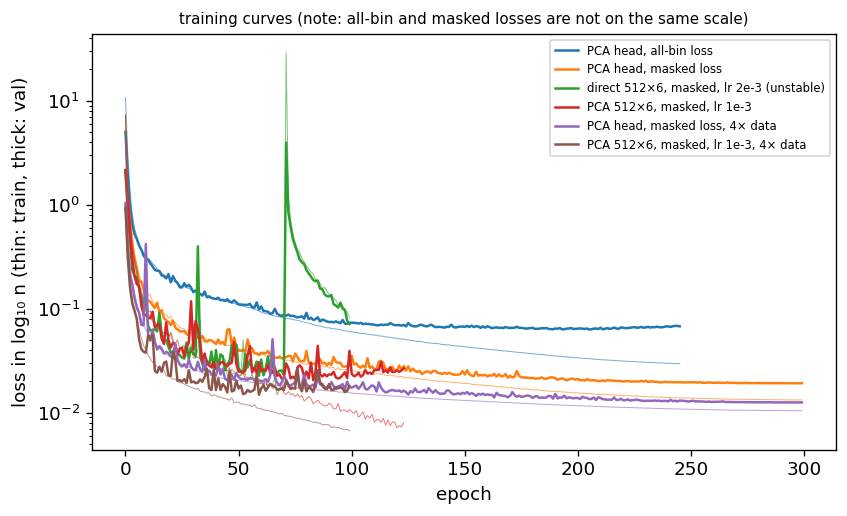

In [11]:
CURVES = ["pca_allbins", "pca_masked", "direct_wide_unstable", "pca_wide", "pca_big", "pca_big_wide"]
fig, ax = plt.subplots(figsize=(8, 4.5))
names = {v: k for k, v in TAGS.items()}
for i, tag in enumerate(CURVES):
    p = MODEL_DIR / f"{tag}_history.json"
    if p.exists():
        h = pd.DataFrame(json.loads(p.read_text()))
        ax.semilogy(h["val_mse"], color=f"C{i}", label=names[tag])
        ax.semilogy(h["train_mse"], color=f"C{i}", lw=0.6, alpha=0.6)
ax.set(xlabel="epoch", ylabel="loss in log₁₀ n (thin: train, thick: val)",
       title="training curves (note: all-bin and masked losses are not on the same scale)")
ax.title.set_fontsize(9)
ax.legend(fontsize=7)
plt.show()

Three findings, all on the held-out test set:

1. **The loss matters more than the output head.** With MSE over *all* bins, both heads reach about 0.04 dex median error. The cliffs down to the 15-dex floor and the floored tails dominate that loss: those bins carry no physics but take most of the gradient. Restricting the loss to bins within 10 dex of each snapshot peak (weight 0.01 elsewhere) halves every error metric. With the same loss, the PCA and direct heads are indistinguishable (0.0187 dex median for both), consistent with the PCA basis offering little compression here.
2. **More capacity does not help at this data size.**
   * The first 512×6 run (learning rate $2\times10^{-3}$) diverged twice. Its early stop reflects that instability, not capacity, so it is kept in the table as a record.
   * At learning rate $10^{-3}$ the 512×6 network trains stably and reaches a good validation loss about 3× faster than the 256×4. It then overfits: training loss keeps falling while validation stalls, and early stopping fires before the cosine schedule anneals.
   * This happens with 4× the data too. The 256×4 network keeps improving through the annealing and generalizes best.
3. **More data helps the most.** Training on 4× more trajectories (58,982 instead of 14,746) lowers the median error from 0.019 to 0.012 dex and the 95th percentile from 0.14 to 0.098 dex (Section 7.5).

The final model is the 256×4 PCA head with the masked loss, trained on the full pool: **`pca_big`**.

## 7. Validation and Failure Modes

All numbers in this section use the 2,048 held-out **test** trajectories, drawn from an independent Sobol stream. Errors are reported in dex on *relevant bins*: bins within 8 dex of each snapshot's peak, which excludes the floored tails.

In [12]:
BEST = cmp["95% |Δ|"].astype(float).idxmin()
best_tag = TAGS[BEST]
ev = np.load(EVAL_DIR / f"{best_tag}.npz")
summary = json.loads((EVAL_DIR / f"{best_tag}.json").read_text())
pred, med, mx = ev["pred"], ev["med"], ev["max"]
print(f"best model: {BEST} ({best_tag})")
pd.Series(summary, name=best_tag).map(lambda v: f"{v:.4g}").to_frame()

best model: PCA head, masked loss, 4× data (pca_big)


,pca_big
test_median_abs_dex,0.01239
test_p95_abs_dex,0.09766
test_median_sample_max_dex,0.2241
test_p95_sample_max_dex,1.001
test_frac_sample_max_lt_0p05,0.04311
test_rmse_all_bins,0.3969
number_rel_err_pred_vs_solver_median,0.02109
number_rel_err_pred_vs_solver_p95,0.1194
number_rel_err_solver_fine_vs_analytic_p95,0.0009555
energy_peak_frac_same_bin,0.5866


### 7.1 Error distribution

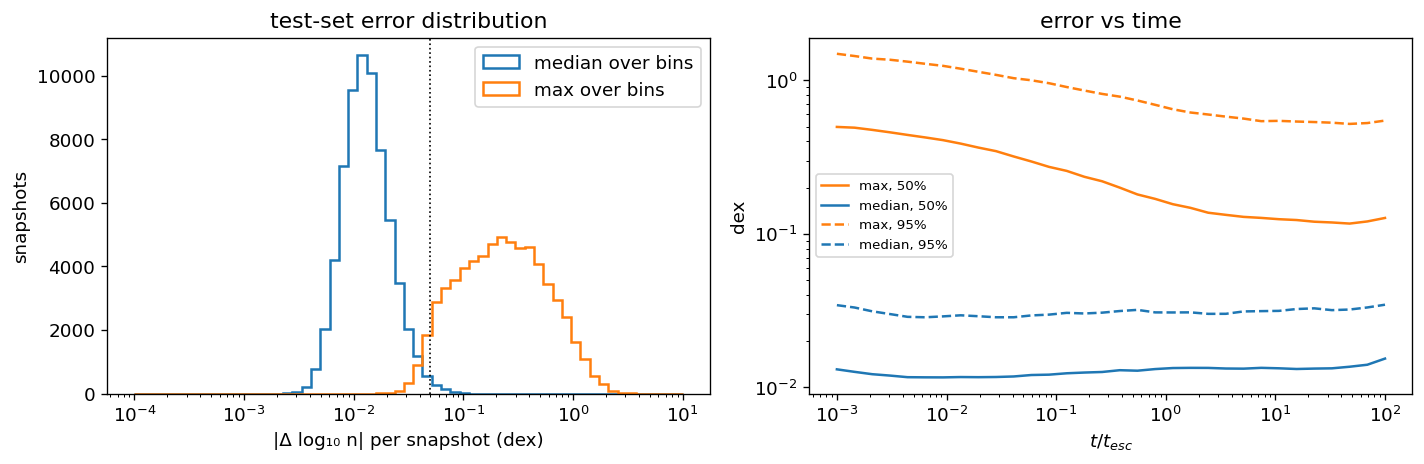

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(-4, 1, 60)
axs[0].hist(med.ravel(), bins=bins, histtype="step", lw=1.5, label="median over bins")
axs[0].hist(mx.ravel(), bins=bins, histtype="step", lw=1.5, label="max over bins")
axs[0].axvline(0.05, color="k", ls=":", lw=1)
axs[0].set(xscale="log", xlabel="|Δ log₁₀ n| per snapshot (dex)", ylabel="snapshots", title="test-set error distribution")
axs[0].legend()
for q, ls in [(50, "-"), (95, "--")]:
    axs[1].semilogx(test.t_out, np.percentile(mx, q, axis=0), ls, color="C1", label=f"max, {q}%")
    axs[1].semilogx(test.t_out, np.percentile(med, q, axis=0), ls, color="C0", label=f"median, {q}%")
axs[1].set(yscale="log", xlabel=r"$t/t_{esc}$", ylabel="dex", title="error vs time")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Over all relevant bins of all 65,536 test snapshots, the median error is **0.012 dex (2.9%)** and the 95th percentile is **0.098 dex**.

The *maximum* error within a snapshot is a much harsher statistic: median 0.22 dex, 95th percentile 1.0 dex. It is set by a handful of bins, and the breakdown by local slope shows which ones. Bins where $|d\log n/d\log\gamma| < 5$ have a median error of 0.011 dex and a 95th percentile of 0.050 dex. The 4.5% of relevant bins on steep edges ($|d\log n/d\log\gamma| > 20$) have a median of 0.15 dex and a 95th percentile of 0.76 dex.

Errors are largest at the earliest snapshots, when the spectrum is still a sharp-edged copy of the injection function, and settle after $t \sim t_{\rm esc}$.

### 7.2 Where does the surrogate fail?

The *typical* error of a trajectory is the median, over its 32 snapshots, of the per-snapshot maximum error. The heatmaps show it as a function of pairs of parameters (top row). The bottom row shows the late-time ($t \ge t_{\rm esc}$) median error, which reflects the smooth, physically relevant part of the spectrum.

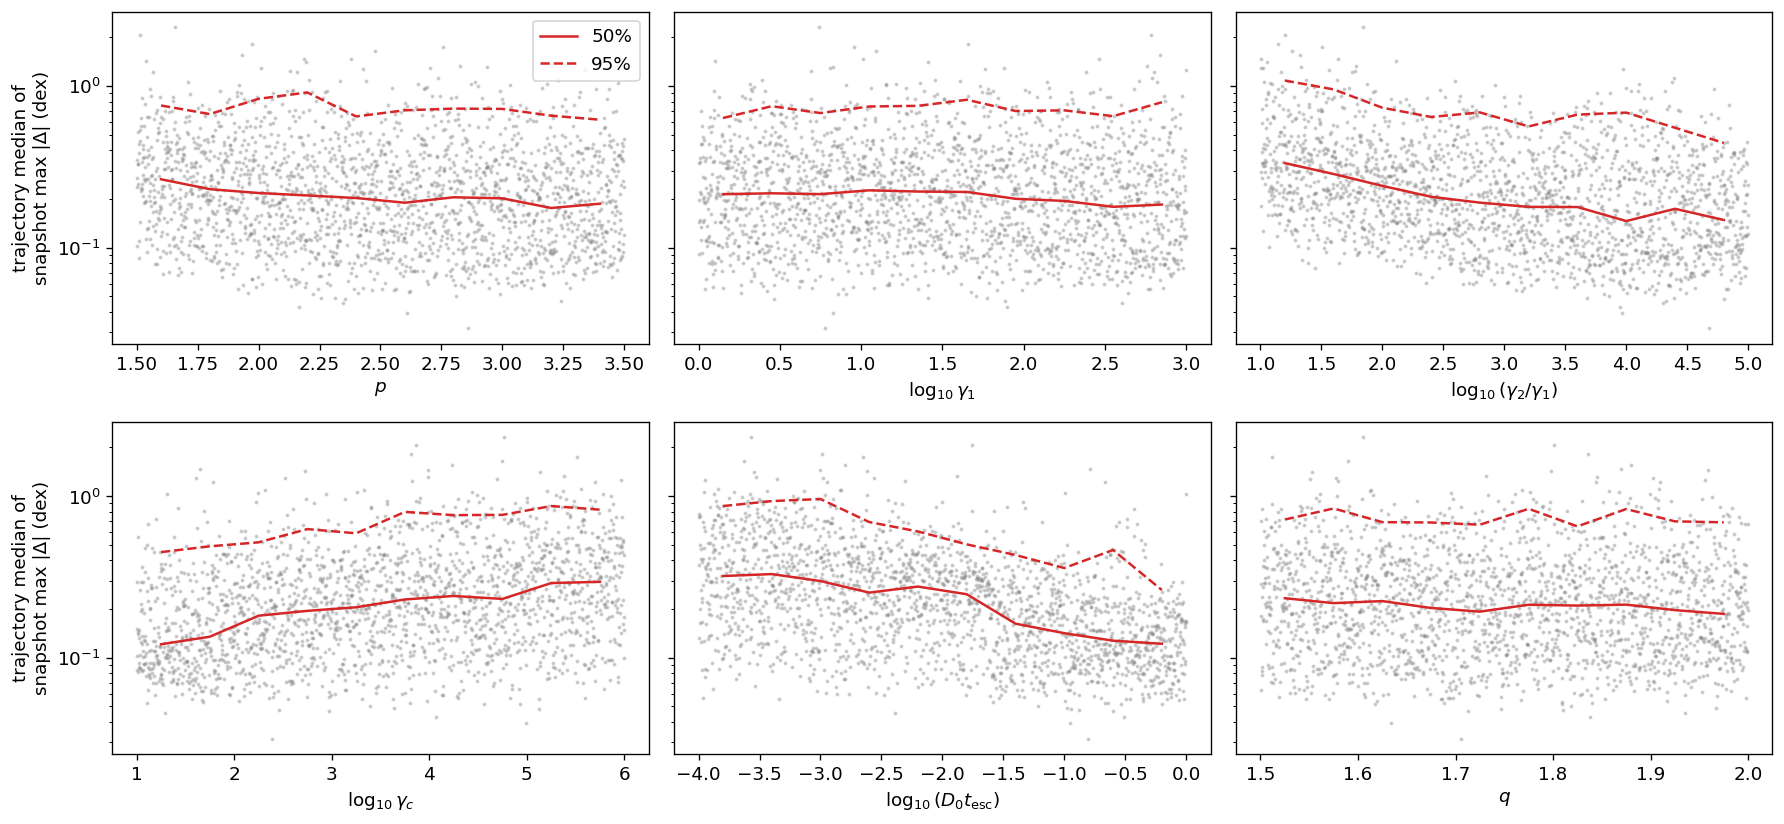

In [14]:
worst_traj = mx.max(axis=1)  # worst snapshot (almost always the earliest)
typ_traj = np.median(mx, axis=1)  # typical snapshot max error along the trajectory
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, j in zip(axs.ravel(), range(cfg.N_PARAMS)):
    x = test.theta[:, j]
    edges = np.linspace(*cfg.PARAM_BOUNDS[j], 11)
    c = 0.5 * (edges[1:] + edges[:-1])
    k = np.digitize(x, edges[1:-1])
    ax.scatter(x, typ_traj, s=2, alpha=0.3, color="gray")
    for q, ls in [(50, "-"), (95, "--")]:
        ax.plot(c, [np.percentile(typ_traj[k == b], q) for b in range(10)], ls, color="C3", label=f"{q}%")
    ax.set(xlabel=cfg.PARAM_LABELS[cfg.PARAM_NAMES[j]], yscale="log")
axs[0, 0].set_ylabel("trajectory median of\nsnapshot max |Δ| (dex)")
axs[1, 0].set_ylabel("trajectory median of\nsnapshot max |Δ| (dex)")
axs[0, 0].legend()
plt.tight_layout()
plt.show()

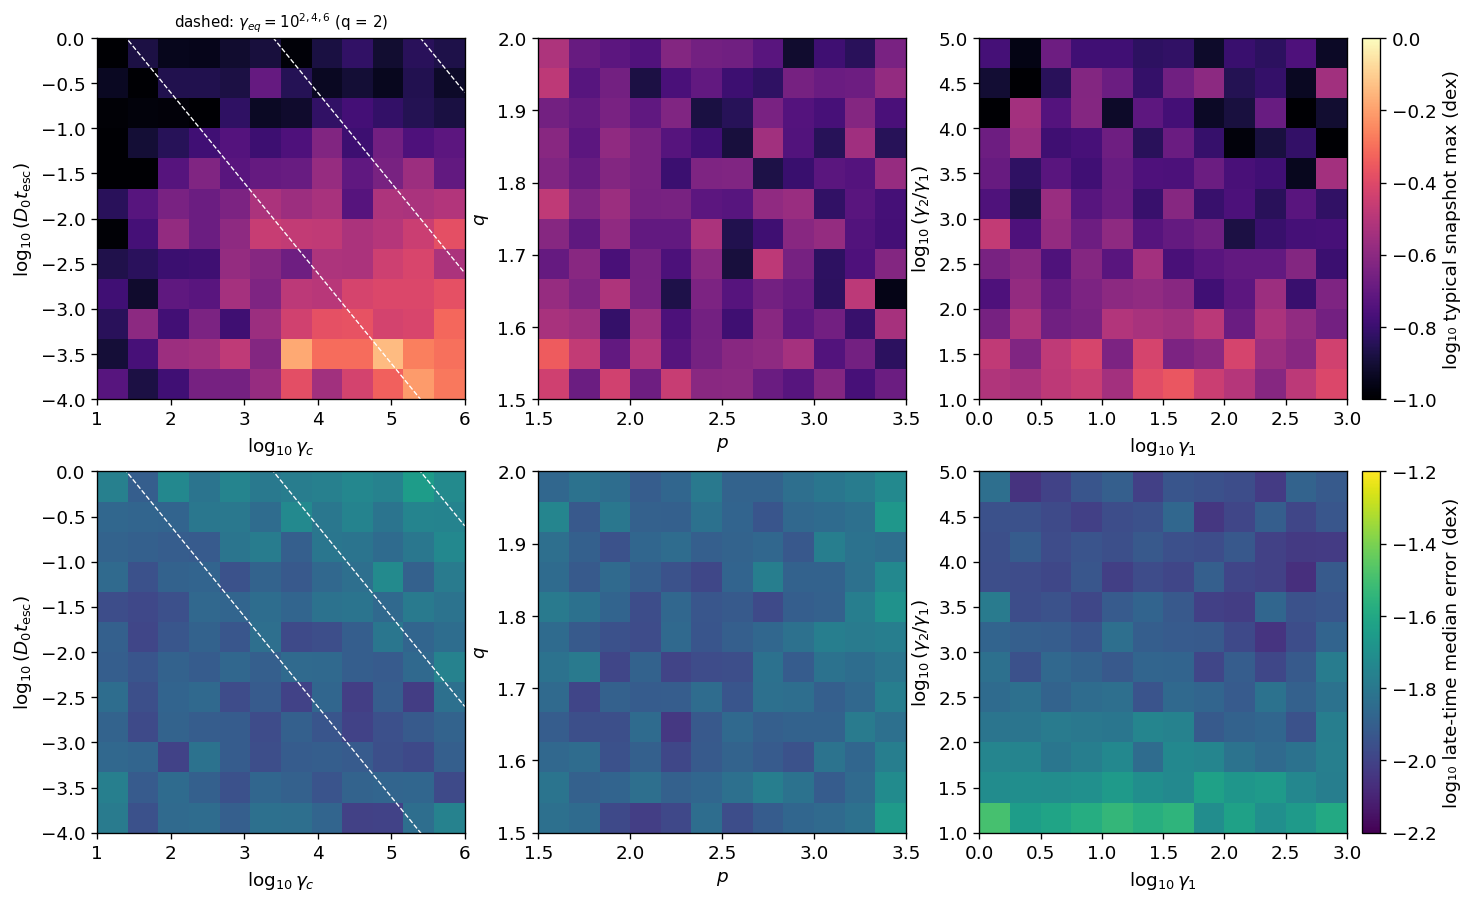

In [15]:
def heat(ax, i, j, val, nb=12, stat=np.median, **kw):
    xe = np.linspace(*cfg.PARAM_BOUNDS[i], nb + 1)
    ye = np.linspace(*cfg.PARAM_BOUNDS[j], nb + 1)
    xi = np.clip(np.digitize(test.theta[:, i], xe) - 1, 0, nb - 1)
    yi = np.clip(np.digitize(test.theta[:, j], ye) - 1, 0, nb - 1)
    H = np.full((nb, nb), np.nan)
    for a in range(nb):
        for b in range(nb):
            s = val[(xi == a) & (yi == b)]
            if len(s):
                H[b, a] = stat(s)
    im = ax.pcolormesh(xe, ye, np.log10(H), shading="flat", **kw)
    ax.set(xlabel=cfg.PARAM_LABELS[cfg.PARAM_NAMES[i]], ylabel=cfg.PARAM_LABELS[cfg.PARAM_NAMES[j]])
    return im

late = test.t_out >= 1.0
late_med = np.median(med[:, late], axis=1)  # median-bin error at t ≥ t_esc
fig, axs = plt.subplots(2, 3, figsize=(16, 8.6))
pairs = [(3, 4), (0, 5), (1, 2)]
for ax, (i, j) in zip(axs[0], pairs):
    im0 = heat(ax, i, j, typ_traj, cmap="magma", vmin=-1.0, vmax=0.0)
for ax, (i, j) in zip(axs[1], pairs):
    im1 = heat(ax, i, j, late_med, cmap="viridis", vmin=-2.2, vmax=-1.2)
# acceleration-cooling equilibrium γ_eq = 4 D0 γc (q = 2) on the first column
lgc = np.linspace(*cfg.PARAM_BOUNDS[3], 50)
for ax in axs[:, 0]:
    for lgeq in [2, 4, 6]:
        ax.plot(lgc, lgeq - lgc - np.log10(4), "w--", lw=0.8)
    ax.set_ylim(*cfg.PARAM_BOUNDS[4])
axs[0, 0].set_title(r"dashed: $\gamma_{eq}=10^{2,4,6}$ (q = 2)", fontsize=9)
fig.colorbar(im0, ax=axs[0], label="log₁₀ typical snapshot max (dex)", pad=0.01)
fig.colorbar(im1, ax=axs[1], label="log₁₀ late-time median error (dex)", pad=0.01)
plt.show()

The failure modes follow the physics:

* **Weak diffusion with weak cooling (low $D_0 t_{\rm esc}$, high $\gamma_c$; bottom right of the top-left panel) is the hardest regime.** Here nothing smooths the injection edges. Cooling only reaches $\gamma \gtrsim \gamma_c t_{\rm esc}/t$, and diffusion is too slow to round the edges, so sharp, parameter-dependent discontinuities persist through the whole trajectory. Moving away from that corner along either axis lowers the error. Strong acceleration (top of the panel) produces smooth, curved spectra that the surrogate reproduces best.
* **Narrow injection ($\gamma_2/\gamma_1 \lesssim 30$) is harder**: the two edges sit only a few bins apart.
* **The power-law index $p$ and the turbulence index $q$ hardly matter.**
* **At late times (bottom row) the error is nearly uniform**, at 0.01–0.02 dex everywhere. The only visible structure is the same narrow-injection trend.

### 7.3 Worst trajectories

The six test trajectories with the largest single-snapshot error, shown at their worst snapshot (red) and two later snapshots:

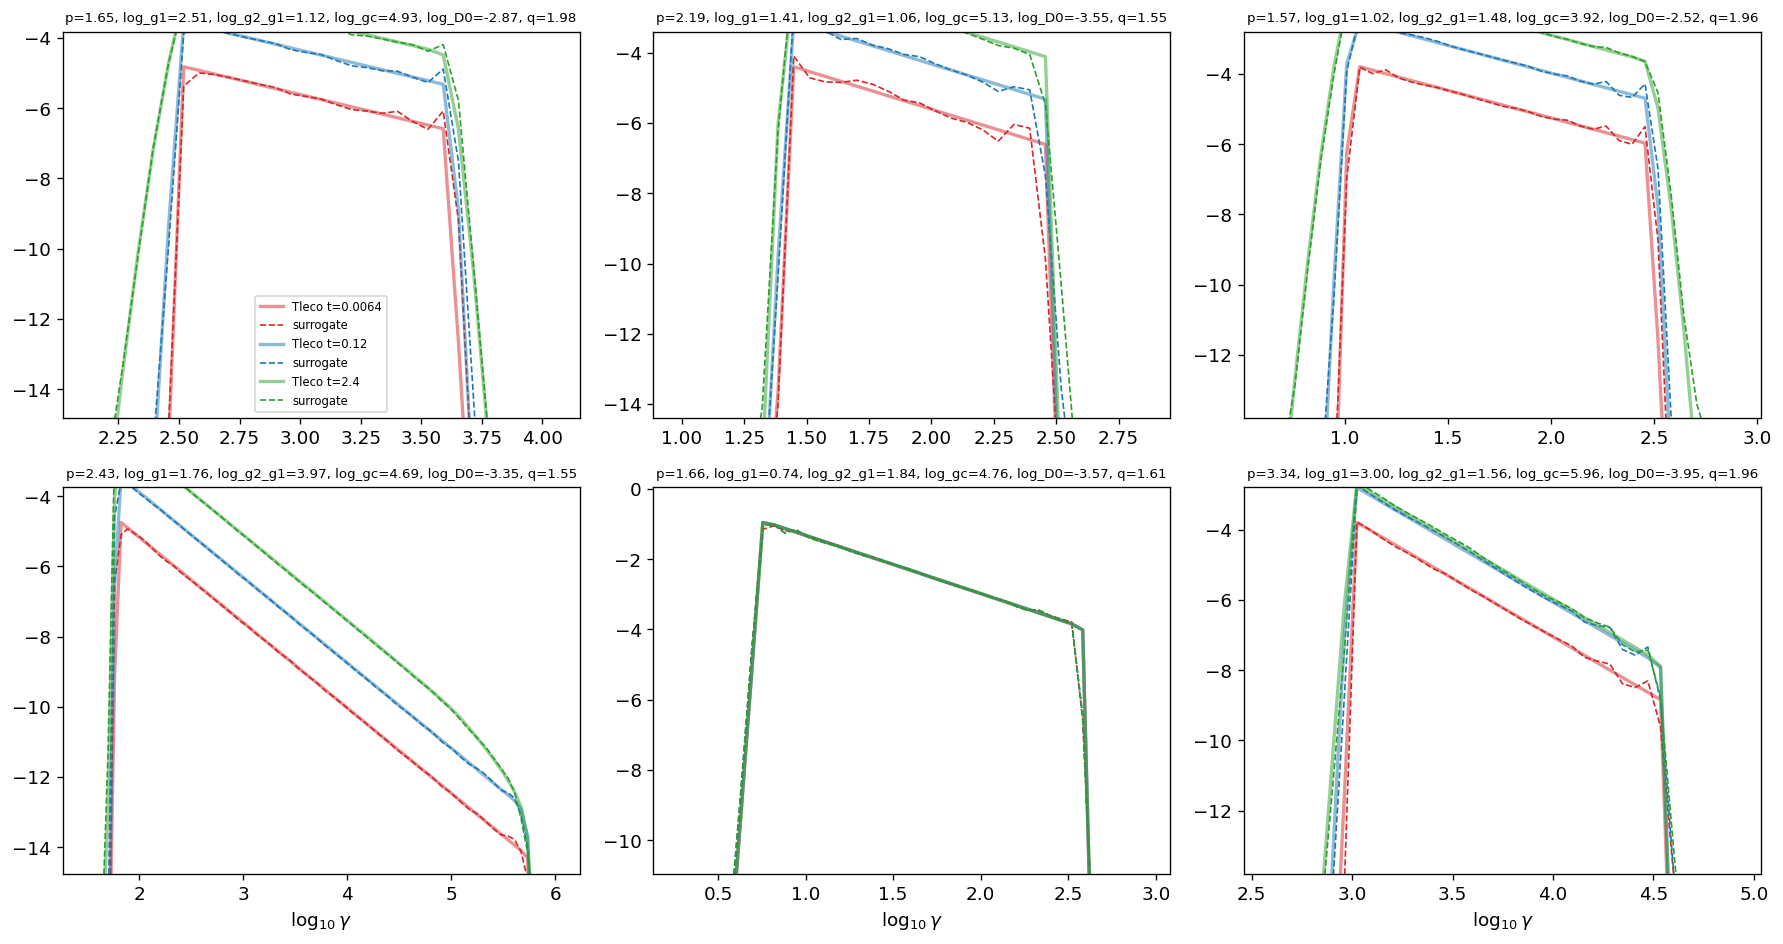

,p,log_g1,log_g2_g1,log_gc,log_D0,q,worst_dex,t_worst
0,1.650,2.513,1.124,4.929,-2.875,1.984,3.461,0.006
1,2.194,1.413,1.057,5.133,-3.546,1.553,3.263,0.001
2,1.570,1.022,1.480,3.923,-2.524,1.957,2.849,0.003
3,2.430,1.764,3.970,4.689,-3.353,1.551,2.639,0.001
4,1.658,0.741,1.844,4.761,-3.569,1.605,2.561,22.638
5,3.337,2.997,1.563,5.960,-3.948,1.956,2.546,0.086


In [16]:
order = np.argsort(worst_traj)[::-1][:6]
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, i in zip(axs.ravel(), order):
    k = np.argmax(mx[i])
    for kk, c in [(k, "C3"), (min(k + 8, cfg.N_TOUT - 1), "C0"), (min(k + 16, cfg.N_TOUT - 1), "C2")]:
        ax.plot(np.log10(G), test.log_n[i, kk], color=c, lw=2, alpha=0.5, label=f"Tleco t={test.t_out[kk]:.2g}")
        ax.plot(np.log10(G), pred[i, kk], "--", color=c, lw=1, label="surrogate")
    top = test.log_n[i, k].max()
    ax.set(ylim=(top - 10, top + 1), xlim=(np.log10(G[test.log_n[i, k] > top - 10]).min() - 0.5,
                                            np.log10(G[test.log_n[i, k] > top - 10]).max() + 0.5),
           title=", ".join(f"{n}={v:.2f}" for n, v in zip(cfg.PARAM_NAMES, test.theta[i])))
    ax.title.set_fontsize(8)
axs[0, 0].legend(fontsize=7)
for ax in axs[1]:
    ax.set_xlabel(r"$\log_{10}\gamma$")
plt.tight_layout()
plt.show()
pd.DataFrame(test.theta[order], columns=cfg.PARAM_NAMES).assign(
    worst_dex=worst_traj[order], t_worst=test.t_out[mx[order].argmax(1)]).round(3)

All six worst trajectories have weak diffusion ($D_0 t_{\rm esc} \le 10^{-2.5}$), and four of them are narrow injection boxes ($\gamma_2/\gamma_1 \lesssim 40$). Their edges therefore stay sharp, in one case even at $t \approx 20\,t_{\rm esc}$, where the three snapshots coincide because the spectrum has reached its steady state.

The surrogate places each edge to within one or two bins, but a one-bin shift of a near-vertical edge costs several dex in that bin. On the plateaus the PCA reconstruction rings at the level of a few tenths of a dex, a Gibbs-like consequence of representing a moving step with a fixed linear basis. Away from the edges, the shape and normalization of the spectrum are reproduced.

### 7.4 Physics diagnostics

1. **Particle number** $N = \int n\,d\gamma$ of the surrogate output vs. Tleco on the same 128-bin grid.
2. **Late-time spectral indices** for cooling-dominated runs ($D_0 t_{\rm esc} < 10^{-3}$): $p$ below $\gamma_c$ and $p+1$ above, measured on windows inside the injection range and away from the breaks.
3. **Position of the energy peak**, the maximum of $\gamma^2 n$. This is what sets the synchrotron peak frequency downstream.

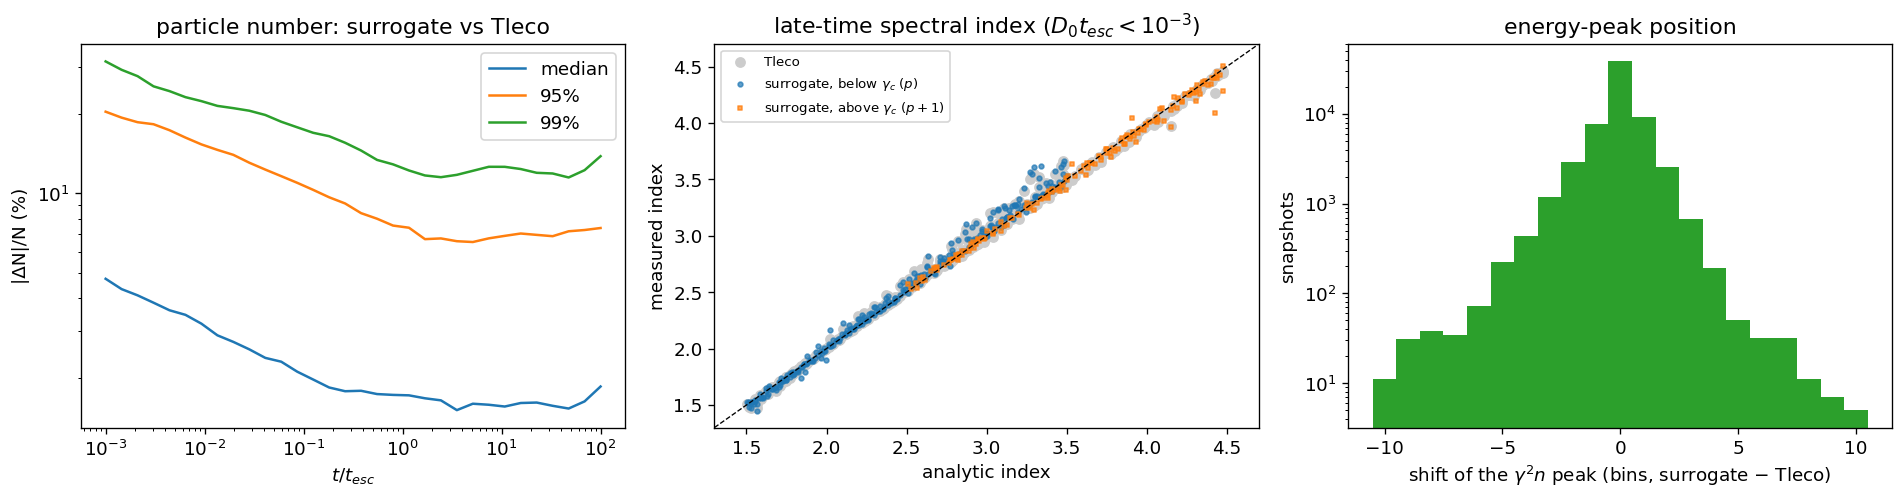

index checks: 431; median |surrogate − Tleco| = 0.010, median |Tleco − analytic| = 0.020
energy peak in the same bin: 58.7%, within one bin (0.063 dex): 84.7% of snapshots


In [17]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
N_rel = ev["N_pred"] / ev["N_true"] - 1
axs[0].semilogx(test.t_out, np.percentile(np.abs(N_rel), [50, 95, 99], axis=0).T * 100, label=["median", "95%", "99%"])
axs[0].set(xlabel=r"$t/t_{esc}$", ylabel="|ΔN|/N (%)", yscale="log", title="particle number: surrogate vs Tleco")
axs[0].legend()
idx = ev["index"]
ok = np.isfinite(idx[:, 2]) & np.isfinite(idx[:, 3])
axs[1].scatter(idx[ok, 4], idx[ok, 2], s=30, color="0.8", label="Tleco")
for w, mk, lab in [(0, "o", r"surrogate, below $\gamma_c$ ($p$)"), (1, "s", r"surrogate, above $\gamma_c$ ($p+1$)")]:
    s = ok & (idx[:, 1] == w)
    axs[1].scatter(idx[s, 4], idx[s, 3], s=8, marker=mk, alpha=0.7, label=lab)
lim = [1.3, 4.7]
axs[1].plot(lim, lim, "k--", lw=0.8)
axs[1].set(xlabel="analytic index", ylabel="measured index", xlim=lim, ylim=lim,
           title=r"late-time spectral index ($D_0 t_{esc}<10^{-3}$)")
axs[1].legend(fontsize=8)
dpk = ev["dpk"]
bw = 8 / (cfg.N_GAMMA - 1)
axs[2].hist(dpk.ravel() / bw, bins=np.arange(-10.5, 11.5, 1), color="C2")
axs[2].set(xlabel=r"shift of the $\gamma^2 n$ peak (bins, surrogate − Tleco)", ylabel="snapshots", yscale="log",
           title="energy-peak position")
plt.tight_layout()
plt.show()
print(f"index checks: {ok.sum()}; median |surrogate − Tleco| = {np.median(np.abs(idx[ok, 3] - idx[ok, 2])):.3f}, "
      f"median |Tleco − analytic| = {np.median(np.abs(idx[ok, 2] - idx[ok, 4])):.3f}")
print(f"energy peak in the same bin: {np.mean(np.abs(dpk) < 0.5 * bw) * 100:.1f}%, within one bin ({bw:.3f} dex): "
      f"{np.mean(np.abs(dpk) < 1.5 * bw) * 100:.1f}% of snapshots")

* **Particle number:** the surrogate's $N(t)$ matches Tleco's to a median 2.1% (95th percentile 12%). This error is larger than the pointwise median, because $N$ is dominated by the lowest-energy part of the spectrum, often right at the injection edge. Nothing in the loss enforces conservation: a physics-informed number-budget penalty is the natural next step.
* **Late-time spectral indices:** recovered to a median 0.010 of Tleco's. That is *smaller* than Tleco's own median offset from the analytic $p$ and $p+1$ (0.020, from the finite measurement windows and residual curvature). The surrogate has learned the cooling break.
* **Energy peak:** the maximum of $\gamma^2 n$ lands in the same bin as Tleco's in 59% of snapshots, and within one bin (0.063 dex) in 85%. The tails of the shift histogram come from flat-topped $\gamma^2 n$ ($p \approx 2$), where the argmax is ill-defined, not from misplaced spectra.

### 7.5 Learning curve

The same architecture (PCA head, 256×4, masked loss) is trained on random subsets of the training trajectories. The validation and test sets are unchanged.

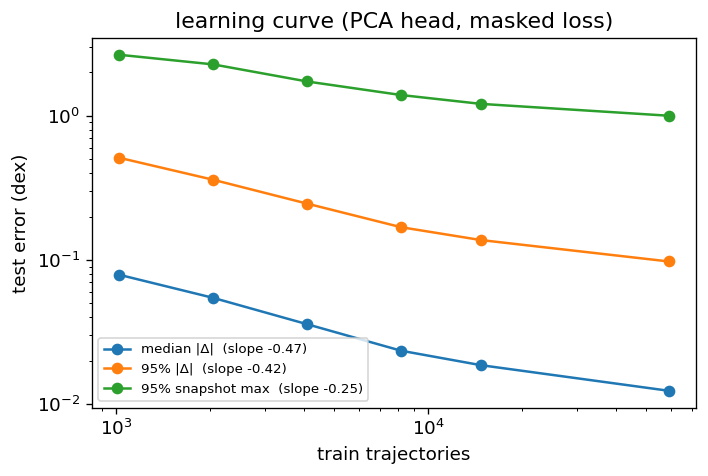

,median |Δ|,95% |Δ|,95% snapshot max
train trajectories,,,
1024,0.0790,0.5115,2.6481
2048,0.0546,0.3600,2.2712
4096,0.0359,0.2459,1.7287
8192,0.0235,0.1688,1.3924
14746,0.0187,0.1375,1.2092
58982,0.0124,0.0977,1.0006


In [18]:
lc = []
for tag in ["lc_1024", "lc_2048", "lc_4096", "lc_8192", "pca_masked", "pca_big"]:
    p = EVAL_DIR / f"{tag}.json"
    if p.exists():
        s = json.loads(p.read_text())
        n_tr = len(FPSurrogate.load(MODEL_DIR / f"{tag}.pt").meta["train_idx"])
        lc.append({"train trajectories": n_tr, "median |Δ|": s["test_median_abs_dex"],
                   "95% |Δ|": s["test_p95_abs_dex"], "95% snapshot max": s["test_p95_sample_max_dex"]})
lc = pd.DataFrame(lc).set_index("train trajectories")
x = lc.index.values.astype(float)
slopes = {c: np.polyfit(np.log10(x), np.log10(lc[c]), 1)[0] for c in lc.columns}
ax = lc.plot(marker="o", logx=True, logy=True, figsize=(6.5, 4))
ax.set(ylabel="test error (dex)", title="learning curve (PCA head, masked loss)")
ax.legend([f"{c}  (slope {slopes[c]:.2f})" for c in lc.columns], fontsize=8)
plt.show()
lc.round(4)

The test error keeps falling with more training data and shows no plateau. The median and 95th-percentile errors scale as $N^{-0.47}$ and $N^{-0.42}$. The 95th-percentile *snapshot maximum* (the edge errors) improves more slowly, as $N^{-0.25}$. At this size the problem is data-limited, which the overfitting of the larger network confirms independently.

Simulations are cheap (about 0.8 CPU-s per trajectory), so more data is the most direct lever on the median error. It is the least effective lever on the edge errors, which need a different representation (Section 8).

### 7.6 Speed

Tleco is timed integrating a full trajectory from $t = 0$ to $100\,t_{\rm esc}$ (32 snapshots, one core). The surrogate is timed on the CPU, unbatched and batched (10,000 snapshots per call).

In [19]:
sp = pd.Series({
    "Tleco, full trajectory (32 snapshots)": summary["solver_traj_s"],
    "surrogate, one snapshot": summary["surrogate_single_s"],
    "surrogate, full trajectory": summary["surrogate_traj_s"],
    "surrogate, batched, per snapshot": summary["surrogate_batched_per_sample_s"],
}, name="seconds")
print(f"speed-up for a full trajectory: {summary['solver_traj_s'] / summary['surrogate_traj_s']:.0f}x; "
      f"batched per snapshot: {summary['solver_traj_s'] / summary['surrogate_batched_per_sample_s']:.0f}x vs. one solver trajectory")
sp.to_frame().style.format("{:.2e}")

speed-up for a full trajectory: 5705x; batched per snapshot: 689375x vs. one solver trajectory


,seconds
"Tleco, full trajectory (32 snapshots)",5.82e-01
"surrogate, one snapshot",5.52e-05
"surrogate, full trajectory",1.02e-04
"surrogate, batched, per snapshot",8.44e-07


## 8. Conclusions and Next Steps

### What was established

1. **A verified physical mapping onto Tleco's solver.** Stochastic acceleration with $D_{pp} = D_0\gamma^q$ enters `fp_findif_difu` as $D = 2D_{pp}$ and $\dot\gamma = \dot\gamma_{\rm cool} - (2+q)D_0\gamma^{q-1}$. It reproduces the acceleration–cooling steady state, the Park & Petrosian (1995) Green's function, the cooling + escape steady state with its $p \to p+1$ break, and the exact particle-number budget.
2. **A characterized solver error floor.** The scheme is first order in $\Delta\gamma$ and $\Delta t$: about 0.08 dex median at 128 bins. Training data is therefore generated on a 4× refined grid (about 0.02 dex) and subsampled.
3. **A surrogate for the parametric solution map.** On 2,048 held-out trajectories it reaches **0.012 dex median and 0.098 dex 95th-percentile error** over the physically relevant part of $n(\gamma, t)$, and about 0.011 dex median on smooth parts of the spectrum. It recovers cooling-break indices more precisely than the analytic-vs-solver offset and runs about **5,700× faster** than Tleco per trajectory (under 1 µs per snapshot batched).
4. **The failure mode is identified and explained.** Errors concentrate on the moving, near-discontinuous injection edges, especially when neither diffusion nor cooling smooths them (low $D_0$, high $\gamma_c$, narrow injection) and at early times. The same structure makes the solution manifold linearly incompressible: about 100 PCA modes are needed.
5. **Methodology lessons.** The loss region matters more than the output head. The problem is data-limited at $1.5\times10^4$–$6\times10^4$ trajectories. Larger MLPs overfit before they help.

### Issues found in Tleco

* `fp_findif_cool`, the fallback used when $\sum D < 10^{-150}$, uses the opposite sign convention for $\dot\gamma$ from `fp_findif_difu`, and is unstable with the documented convention. This is worth an upstream fix.
* Particles leak through the $\gamma = 1$ boundary when injection starts near $\gamma_1 \approx 1$ (up to 33% of the particles in this design). This is a known limitation of the ultra-relativistic equation near $\gamma \sim 1$, but it should be documented for users.

### Next steps

* **Edges:** a coordinate-based model that takes $(\theta, t, \gamma)$ and returns $n$ (a DeepONet or neural field) can represent translating edges without a fixed basis. So can predicting the edge positions explicitly and warping the $\gamma$ grid. Either is the most promising fix for the dominant failure mode.
* **Conservation:** add a particle-number penalty, $\int n\,d\gamma$ vs. the solver's budget, as a physics-informed term, and measure whether it improves $N(t)$ without hurting the pointwise error.
* **Stage 2:** couple the surrogate's $n(\gamma, t)$ to Tleco's radiation kernels, then build the full $(\Gamma, \sigma, f_{\rm rec}, L_{\rm jet}, \dot m) \to$ SED emulator of the RHG21 model and use it for Bayesian inference.

## 9. References

- Chang, J. S., & Cooper, G. 1970, J. Comput. Phys., 6, 1
- Davis, Z., Rueda-Becerril, J. M., & Giannios, D. 2022, MNRAS, 513, 5766
- Davis, Z., Rueda-Becerril, J. M., & Giannios, D. 2024, ApJ, 976, 182 (Tleco)
- Ghisellini, G., & Tavecchio, F. 2009, MNRAS, 397, 985
- Park, B. T., & Petrosian, V. 1995, ApJ, 446, 699
- Rueda-Becerril, J. M., Harrison, A. O., & Giannios, D. 2021, MNRAS, 501, 4092 (RHG21)
- Spurio Mancini, A., Piras, D., Alsing, J., Joachimi, B., & Hobson, M. P. 2022, MNRAS, 511, 1771 (CosmoPower)